# Support for Worksheet 08: Visualizing Data

Required chart tasks and verification for the completed worksheet. Inputs are exact local source copies. Personal Explain It responses and the learner's submission checklist remain pending in the worksheet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from pathlib import Path

OUT = Path('..') / 'Worksheet-OutputFiles'
OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
titanic = pd.read_csv('titanic.csv')
poke = pd.read_csv('pokemon.csv')
penguins = pd.read_csv('penguins.csv')
SPECIES_ORDER = ['Adelie', 'Chinstrap', 'Gentoo']
PALETTE = dict(zip(SPECIES_ORDER, sns.color_palette('colorblind', 3)))

## Task 1: Reusable histogram function

The function draws on the provided axes. If an axes already uses a log x-scale, it excludes nonpositive values, uses geometric bins, and calculates reference statistics on the same plotted subset. Variables have different units, so these four axes use appropriate separate scales rather than sharing unrelated units.

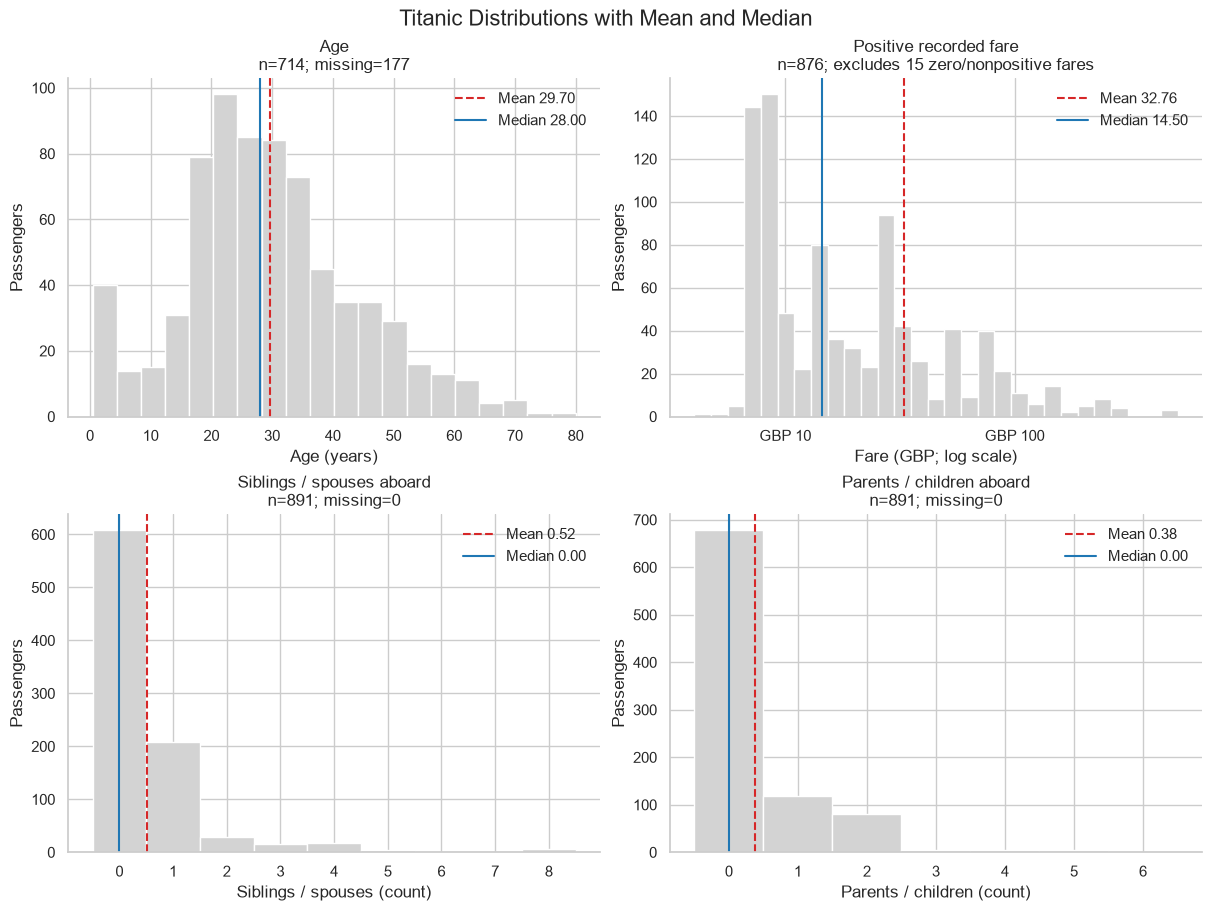

In [2]:
def plot_distribution(ax, series, title, unit):
    values = series.dropna()
    omitted_missing = series.isna().sum()
    if ax.get_xscale() == 'log':
        omitted_nonpositive = values.le(0).sum()
        values = values.loc[values > 0]
        bins = np.geomspace(values.min(), values.max(), 30)
        subtitle = f'n={len(values)}; excludes {omitted_nonpositive} zero/nonpositive fares'
        ax.xaxis.set_major_formatter(StrMethodFormatter('GBP {x:,.0f}'))
    else:
        subtitle = f'n={len(values)}; missing={omitted_missing}'
        if values.mod(1).eq(0).all() and values.max() - values.min() < 20:
            bins = np.arange(values.min() - .5, values.max() + 1.5)
            ax.set_xticks(range(int(values.min()), int(values.max()) + 1))
        else:
            bins = 20
    ax.hist(values, bins=bins, color='lightgray', edgecolor='white')
    ax.axvline(values.mean(), color='tab:red', linestyle='--', label=f'Mean {values.mean():.2f}')
    ax.axvline(values.median(), color='tab:blue', label=f'Median {values.median():.2f}')
    ax.set(title=f'{title}\n{subtitle}', xlabel=unit, ylabel='Passengers')
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout='constrained')
axes[0, 1].set_xscale('log')
for ax, column, title, unit in zip(axes.flat, ['Age', 'Fare', 'SibSp', 'Parch'],
                                  ['Age', 'Positive recorded fare', 'Siblings / spouses aboard', 'Parents / children aboard'],
                                  ['Age (years)', 'Fare (GBP; log scale)', 'Siblings / spouses (count)', 'Parents / children (count)']):
    plot_distribution(ax, titanic[column], title, unit)
fig.suptitle('Titanic Distributions with Mean and Median', fontsize=16)
fig.savefig(OUT / 'titanic_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

## Task 2: Summary table, stacked bars, and long form

Legendary,False,True
Generation,,
1,160,6
2,101,5
3,142,18
4,108,13
5,150,15
6,74,8


Legendary,False,True
Generation,,
1,0.9639,0.0361
2,0.9528,0.0472
3,0.8875,0.1125
4,0.8926,0.1074
5,0.9091,0.0909
6,0.9024,0.0976


,Generation,Legendary,count
0,1,False,160
1,2,False,101
2,3,False,142
3,4,False,108
4,5,False,150
5,6,False,74
6,1,True,6
7,2,True,5
8,3,True,18
9,4,True,13


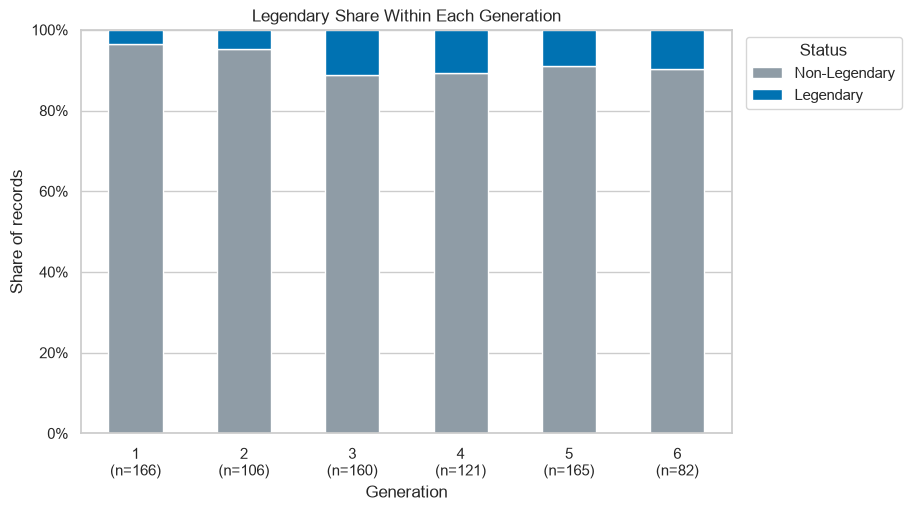

In [3]:
generation_counts = pd.crosstab(poke['Generation'], poke['Legendary']).reindex(columns=[False, True])
generation_shares = pd.crosstab(poke['Generation'], poke['Legendary'], normalize='index').reindex(columns=[False, True])
generation_long = (generation_counts.reset_index().melt(id_vars='Generation',
                    var_name='Legendary', value_name='count'))
generation_long['Legendary'] = generation_long['Legendary'].astype(bool)
display(generation_counts)
display(generation_shares.round(4))
display(generation_long)
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
generation_shares.rename(columns={False: 'Non-Legendary', True: 'Legendary'}).plot.bar(
    stacked=True, ax=ax, color=['#8f9ca6', '#0072b2'], rot=0)
ax.set_xticklabels([f'{generation}\n(n={int(generation_counts.loc[generation].sum())})'
                    for generation in generation_shares.index])
ax.set(title='Legendary Share Within Each Generation', xlabel='Generation', ylabel='Share of records', ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.legend(title='Status', bbox_to_anchor=(1.01, 1), loc='upper left')
fig.savefig(OUT / 'legendary_share_by_generation.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

## Task 3: Four fair distribution views

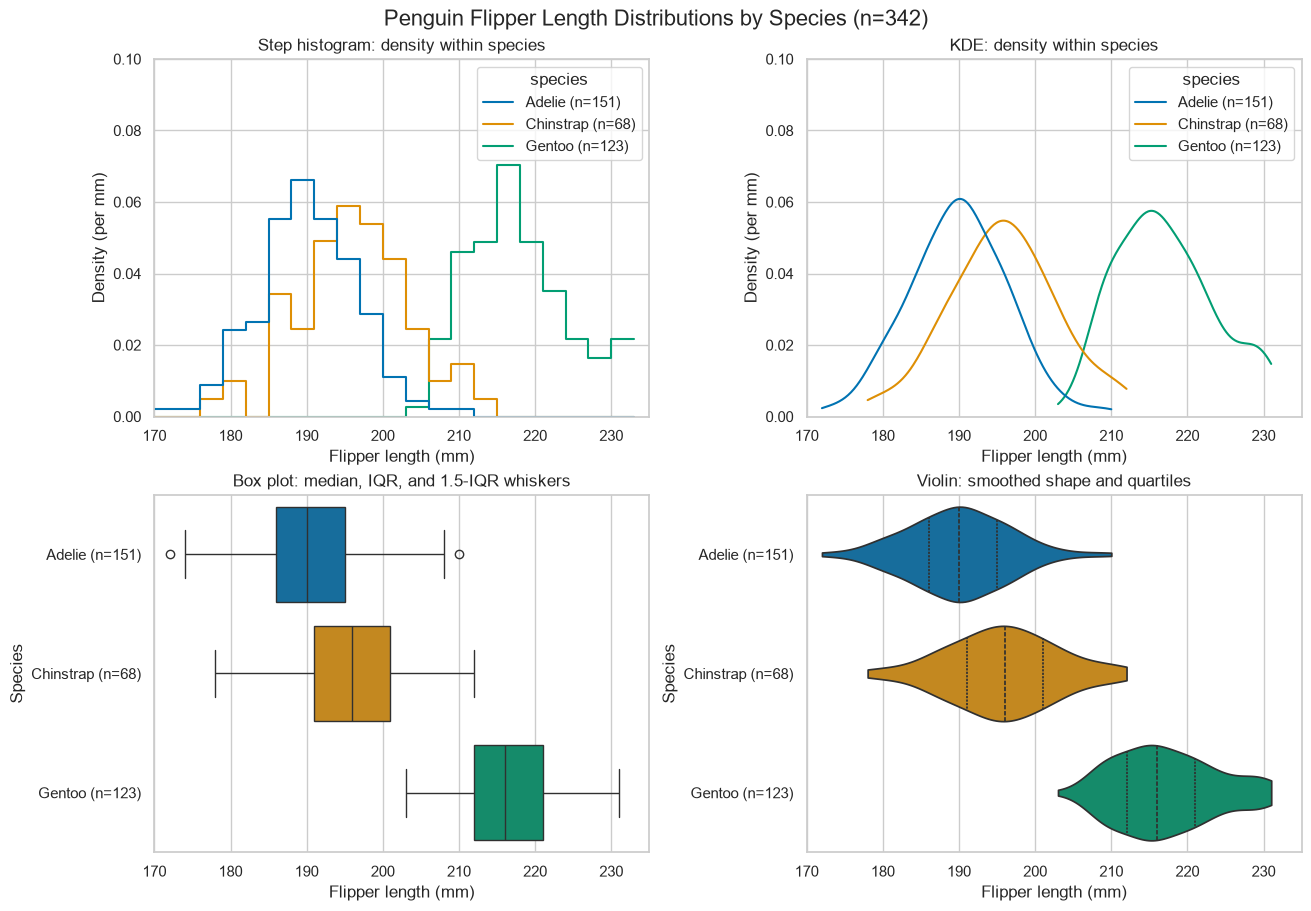

In [4]:
flippers = penguins.dropna(subset=['species', 'flipper_length_mm']).copy()
species_counts = flippers['species'].value_counts().reindex(SPECIES_ORDER)
species_labels = [f'{species} (n={int(species_counts[species])})' for species in SPECIES_ORDER]
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
sns.histplot(data=flippers, x='flipper_length_mm', hue='species', hue_order=SPECIES_ORDER,
             palette=PALETTE, bins=np.arange(170, 236, 3), element='step', fill=False,
             stat='density', common_norm=False, ax=axes[0, 0])
sns.kdeplot(data=flippers, x='flipper_length_mm', hue='species', hue_order=SPECIES_ORDER,
            palette=PALETTE, common_norm=False, cut=0, ax=axes[0, 1])
for ax, title in zip(axes[0], ['Step histogram: density within species', 'KDE: density within species']):
    ax.set(title=title, xlabel='Flipper length (mm)', ylabel='Density (per mm)', xlim=(170, 235), ylim=(0, .1))
    legend = ax.get_legend()
    for label, replacement in zip(legend.get_texts(), species_labels):
        label.set_text(replacement)
sns.boxplot(data=flippers, x='flipper_length_mm', y='species', hue='species',
            order=SPECIES_ORDER, hue_order=SPECIES_ORDER, palette=PALETTE, legend=False, ax=axes[1, 0])
sns.violinplot(data=flippers, x='flipper_length_mm', y='species', hue='species',
               order=SPECIES_ORDER, hue_order=SPECIES_ORDER, palette=PALETTE, legend=False,
               inner='quart', cut=0, density_norm='area', common_norm=False, ax=axes[1, 1])
for ax, title in zip(axes[1], ['Box plot: median, IQR, and 1.5-IQR whiskers', 'Violin: smoothed shape and quartiles']):
    ax.set(title=title, xlabel='Flipper length (mm)', ylabel='Species', xlim=(170, 235))
    ax.set_yticks(range(3), species_labels)
fig.suptitle('Penguin Flipper Length Distributions by Species (n=342)', fontsize=16)
fig.savefig(OUT / 'flipper_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

## Task 4: Aggregate association versus within-species association

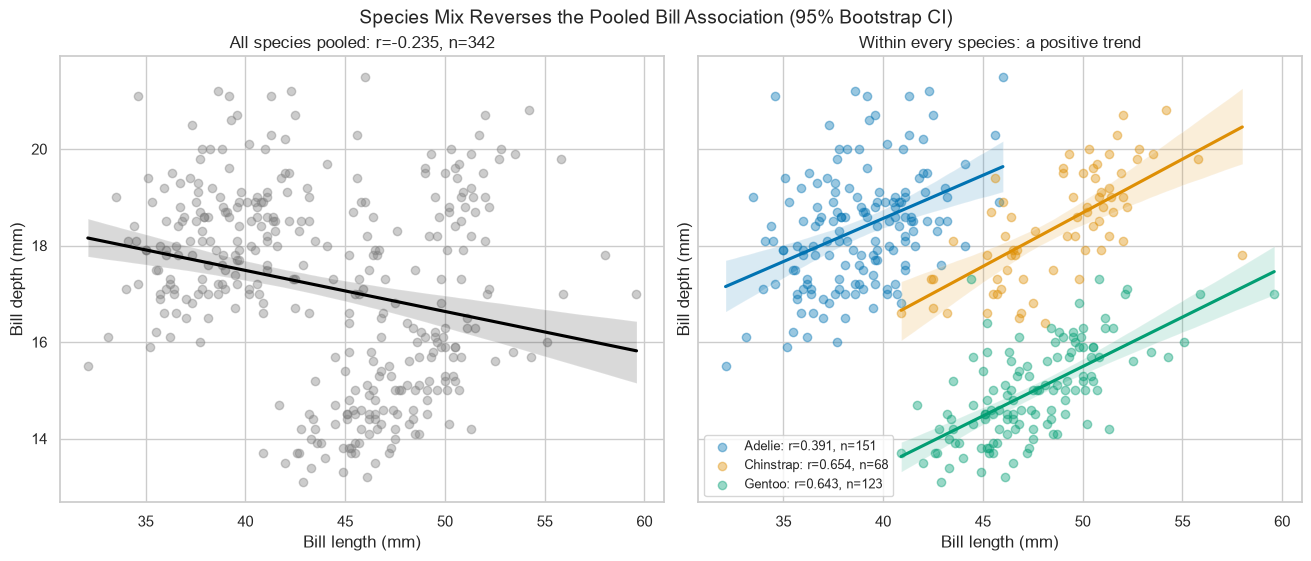

,species,n,r
0,Adelie,151,0.391492
1,Chinstrap,68,0.653536
2,Gentoo,123,0.643384


Species composition explains the direction reversal. These observations do not establish causation.


In [5]:
bills = penguins.dropna(subset=['species', 'bill_length_mm', 'bill_depth_mm']).copy()
bill_summary = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True, layout='constrained')
r_all = bills['bill_length_mm'].corr(bills['bill_depth_mm'])
sns.regplot(data=bills, x='bill_length_mm', y='bill_depth_mm', seed=2026, n_boot=2000,
            scatter_kws={'color': 'gray', 'alpha': .4}, line_kws={'color': 'black'}, ax=axes[0])
axes[0].set_title(f'All species pooled: r={r_all:.3f}, n={len(bills)}')
for species in SPECIES_ORDER:
    group = bills.loc[bills['species'] == species]
    r = group['bill_length_mm'].corr(group['bill_depth_mm'])
    bill_summary.append({'species': species, 'n': len(group), 'r': r})
    sns.regplot(data=group, x='bill_length_mm', y='bill_depth_mm', color=PALETTE[species],
                seed=2026, n_boot=2000, scatter_kws={'alpha': .4},
                label=f'{species}: r={r:.3f}, n={len(group)}', ax=axes[1])
axes[1].set_title('Within every species: a positive trend')
axes[1].legend(loc='lower left', fontsize=9)
for ax in axes:
    ax.set(xlabel='Bill length (mm)', ylabel='Bill depth (mm)')
fig.suptitle('Species Mix Reverses the Pooled Bill Association (95% Bootstrap CI)', fontsize=14)
fig.savefig(OUT / 'penguin_paradox.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
bill_summary = pd.DataFrame(bill_summary)
display(bill_summary)
print('Species composition explains the direction reversal. These observations do not establish causation.')

## Task 5: Makeover using a robust center and a clear finding

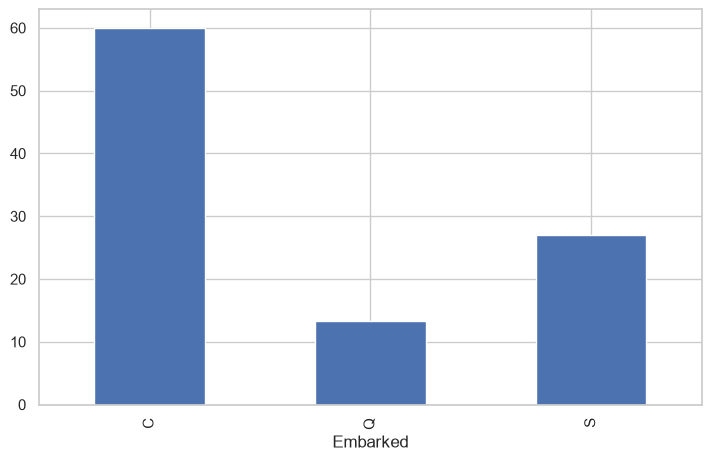

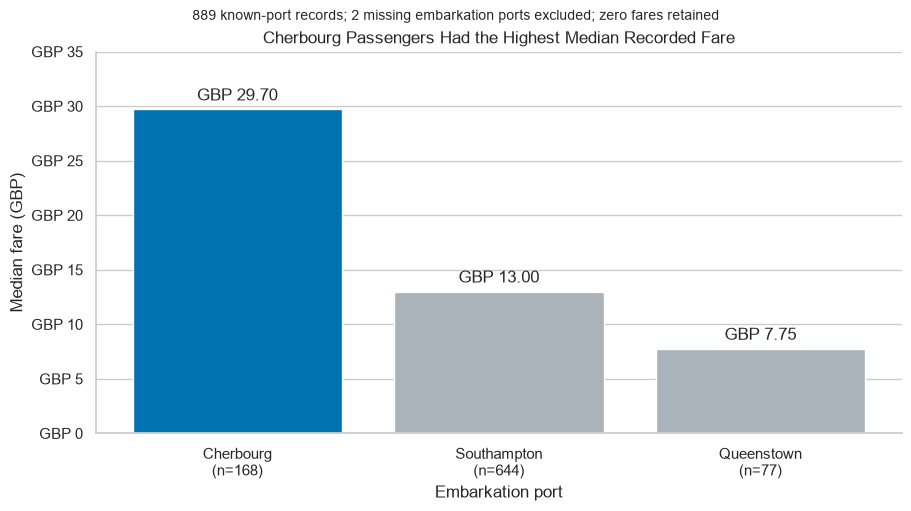

,count,mean,median
Embarked,,,
C,168,59.954144,29.70
S,644,27.079812,13.00
Q,77,13.276030,7.75


Medians describe recorded ticket fares; port differences may reflect ticket class or other group composition, rather than a port effect.


In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5), layout='constrained')
titanic.groupby('Embarked')['Fare'].mean().plot.bar(ax=ax)
fig.savefig(OUT / 'embarked_fare_before.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

port_names = {'C': 'Cherbourg', 'Q': 'Queenstown', 'S': 'Southampton'}
port_summary = (titanic.dropna(subset=['Embarked', 'Fare']).groupby('Embarked')['Fare']
                .agg(['count', 'mean', 'median']).sort_values('median', ascending=False))
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
labels = [f'{port_names[port]}\n(n={int(port_summary.loc[port, "count"])})' for port in port_summary.index]
bars = ax.bar(labels, port_summary['median'], color=['#0072b2' if port == 'C' else '#aab3b9' for port in port_summary.index])
ax.bar_label(bars, labels=[f'GBP {value:.2f}' for value in port_summary['median']], padding=4)
ax.set(title='Cherbourg Passengers Had the Highest Median Recorded Fare', xlabel='Embarkation port', ylabel='Median fare (GBP)', ylim=(0, 35))
ax.yaxis.set_major_formatter(StrMethodFormatter('GBP {x:,.0f}'))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', visible=False)
ax.set_axisbelow(True)
fig.suptitle('889 known-port records; 2 missing embarkation ports excluded; zero fares retained', fontsize=10)
fig.savefig(OUT / 'embarked_fare_after.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
display(port_summary)
print('Medians describe recorded ticket fares; port differences may reflect ticket class or other group composition, rather than a port effect.')

## Independent verification

In [7]:
import csv
import math
import statistics
from collections import Counter, defaultdict

def records(filename):
    with open(filename, newline='', encoding='utf-8') as handle:
        return list(csv.DictReader(handle))

tr, pr, kr = records('titanic.csv'), records('penguins.csv'), records('pokemon.csv')
age_ref = [float(row['Age']) for row in tr if row['Age'] != '']
paid_ref = [float(row['Fare']) for row in tr if row['Fare'] != '' and float(row['Fare']) > 0]
assert len(age_ref) == 714 and len(paid_ref) == 876
assert sum(row['Fare'] != '' and float(row['Fare']) == 0 for row in tr) == 15
for values, series in [(age_ref, titanic['Age'].dropna()), (paid_ref, titanic.loc[titanic['Fare'] > 0, 'Fare'])]:
    assert math.isclose(statistics.mean(values), series.mean())
    assert statistics.median(values) == series.median()
count_ref = Counter((int(row['Generation']), row['Legendary'].lower() == 'true') for row in kr)
for generation in generation_counts.index:
    for legendary in [False, True]:
        assert generation_counts.loc[generation, legendary] == count_ref[(generation, legendary)]
assert np.allclose(generation_shares.sum(axis=1), 1)
pd.testing.assert_frame_equal(generation_long.pivot(index='Generation', columns='Legendary', values='count'), generation_counts)
assert generation_long['count'].sum() == 800
for species in SPECIES_ORDER:
    source = [row for row in pr if row['species'] == species and row['flipper_length_mm'] != '']
    assert species_counts[species] == len(source)
bill_pairs = [row for row in pr if row['bill_length_mm'] != '' and row['bill_depth_mm'] != '' and row['species'] != '']
def independent_r(rows):
    return statistics.correlation([float(row['bill_length_mm']) for row in rows], [float(row['bill_depth_mm']) for row in rows])
assert len(bill_pairs) == 342 and math.isclose(r_all, independent_r(bill_pairs)) and r_all < 0
for row in bill_summary.itertuples(index=False):
    source = [record for record in bill_pairs if record['species'] == row.species]
    assert row.n == len(source) and math.isclose(row.r, independent_r(source)) and row.r > 0
port_values = defaultdict(list)
for row in tr:
    if row['Embarked'] != '' and row['Fare'] != '':
        port_values[row['Embarked']].append(float(row['Fare']))
for port, values in port_values.items():
    assert len(values) == port_summary.loc[port, 'count']
    assert statistics.median(values) == port_summary.loc[port, 'median']
    assert math.isclose(statistics.mean(values), port_summary.loc[port, 'mean'])
assert sum(len(values) for values in port_values.values()) == 889
pd.testing.assert_frame_equal(titanic, pd.read_csv('titanic.csv'))
pd.testing.assert_frame_equal(poke, pd.read_csv('pokemon.csv'))
pd.testing.assert_frame_equal(penguins, pd.read_csv('penguins.csv'))
expected = ['titanic_distributions.png', 'legendary_share_by_generation.png', 'flipper_distributions.png',
            'penguin_paradox.png', 'embarked_fare_before.png', 'embarked_fare_after.png']
assert all((OUT / filename).stat().st_size > 1000 for filename in expected)
print('PASS: source-derived means/medians, honest positive-fare log subset, generation crosstab/melt, group counts/correlations, port makeover, and six PNGs.')
print('The five personal Explain It responses remain pending; no personal checklist items are marked complete.')
for path in sorted(OUT.glob('*.png')):
    print(path)

PASS: source-derived means/medians, honest positive-fare log subset, generation crosstab/melt, group counts/correlations, port makeover, and six PNGs.
The five personal Explain It responses remain pending; no personal checklist items are marked complete.
..\Worksheet-OutputFiles\embarked_fare_after.png
..\Worksheet-OutputFiles\embarked_fare_before.png
..\Worksheet-OutputFiles\flipper_distributions.png
..\Worksheet-OutputFiles\legendary_share_by_generation.png
..\Worksheet-OutputFiles\penguin_paradox.png
..\Worksheet-OutputFiles\titanic_distributions.png
